> **AI for RO · phase 3: fouling meets the sun** — part of Project 3 of [chemai](https://github.com/EngMtaleb/chemai/tree/main/projects/p03_ai_for_ro). This notebook was written as “phase 4”: its code, its printed lines and the declaration appended at the end keep the names they were written with. Working names → the episode: phase 3 → **phase 1**, phase 3b → **phase 1B**, phase 4 → **phase 3**, phase 1 → **the lab study**; phase 2 keeps its number.

# Fouling meets the sun — phase 3

**Questions**
1. How much energy does a fouled train cost, on the phase-2 plant's own train?
2. Where does one real plant's fouling sit on that map — and what does it cost there?
3. On a plant that runs on the sun, who pays that extra energy: the sun or the grid?
4. Does running on the sun change when energy alone would justify a cleaning?

**How the two halves of the project meet here.** Phase 2 built a solar RO plant hour by hour (twice the demand, 0.8 kWp of
panels per m³/day, a 12-hour product-water tank). Project 5 (when to stop, kept in this repository’s history) asked, on one real plant's 15 cleaning cycles, when the energy a
fouled train wastes would pay for a cleaning — and found it almost never did. Phase 3 puts the real plant's fouling on the
phase-2 train, runs a fouled year under the sun, and asks Project 5's question again with the sun paying part of the energy.

**Declared before the run** (appendix): the inputs, the four computations, the checks and four expectations, E1–E4. Nothing
new is fitted.

**What it cannot say:** the real plant's record gives fouling as *relative* rises (ΔP over its commissioning baseline,
permeability loss), not absolute pressures. Putting them on our train is a what-if: "if our train fouled the way this plant
did". Holding a fouled state for a whole year shows the most that state can do; it is not a schedule.

Run all: about 15–25 minutes (it computes every map point, and five years hour by hour for both strategies — clean, three
fouled states and one sensitivity).

In [1]:
import subprocess, sys
try:
    import pvlib
except ImportError:                                   # Colab: one library to add
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pvlib==0.15.2"], check=True)
    import pvlib
import hashlib, io, itertools, time, urllib.request, zipfile
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
%config InlineBackend.figure_format = "retina"
pd.set_option("display.width", 200)
INK, INK2, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
BLUES = LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
plt.rcParams.update({"font.size": 10, "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "xtick.color": INK2,
                     "ytick.color": INK2, "figure.facecolor": SURF, "axes.facecolor": SURF})
def style(ax):
    ax.grid(color=GRID, lw=0.8); ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
print("numpy", np.__version__, "| pandas", pd.__version__, "| pvlib", pvlib.__version__,
      "\n(the numbers in the text came from numpy 2.5.3, pandas 3.0.5, pvlib 0.15.2; other versions can move the last digits)")

numpy 2.5.3 | pandas 3.0.5 | pvlib 0.15.2 
(the numbers in the text came from numpy 2.5.3, pandas 3.0.5, pvlib 0.15.2; other versions can move the last digits)


## 1 · Download the data, and Project 5's code

- **Sun and sea** (as in phase 2): NASA POWER — hourly sun, air temperature and wind at 29.37 N, 47.98 E, and the daily sea skin
  temperature at 29.0 N, 48.75 E, 2015–2024. Checked against the SHA-256 of the files used here.
- **The plant** (as in phase 1): the daily indicator table of Su, Meng & Chang (2026), *Membranes* 16(8) 257
  (doi:10.3390/membranes16080257), data doi:10.5281/zenodo.21055948, CC BY 4.0 — 3 trains, day 0–771, 18 cleanings.
  `dp_pct`: the feed-channel ΔP's rise over a fixed commissioning baseline. `flux_pct`: the loss of 25 °C specific flux (water
  permeability), floored at 0. `ndp_pct`: the net driving pressure's rise since the last cleaning (reset at each cleaning).
- **Project 5's cleaning economics**, imported from the project repository at a fixed commit: its cycle inputs, its energy
  penalty, its rule and square-root law (`chemai.models.stopping.interval_economics`).

In [2]:
D = Path("data"); D.mkdir(exist_ok=True)
def get(url, timeout=600):
    return urllib.request.urlopen(urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"}), timeout=timeout).read()

# 1. sun and sea, NASA POWER (as in phase 2)
API = "https://power.larc.nasa.gov/api/temporal/"
FILES = {
    "sun": (API + "hourly/point?parameters=ALLSKY_SFC_SW_DWN,ALLSKY_SFC_SW_DNI,ALLSKY_SFC_SW_DIFF,CLRSKY_SFC_SW_DWN,T2M,WS10M"
                  "&community=RE&longitude=47.98&latitude=29.37&start=20150101&end=20241231&format=CSV&time-standard=UTC",
            "POWER_Point_Hourly_20150101_20241231_029d37N_047d98E_UTC.csv",
            "73b1e74e0f2472566cfbe3b1e5792c0fa38114ca72582f782990bed6f4dbab95"),
    "sea": (API + "daily/point?parameters=TS,T2M&community=RE&longitude=48.75&latitude=29.0&start=20150101&end=20241231&format=CSV",
            "POWER_Point_Daily_20150101_20241231_029d00N_048d75E_LST.csv",
            "a0bb8657a651064a1e5246573c4dd4f5ad19c5a13cb0314cf5642779cd887c37")}
for key, (url, name, sha) in FILES.items():
    f = D / name
    if not f.exists():
        f.write_bytes(get(url))
    same = hashlib.sha256(f.read_bytes()).hexdigest() == sha
    print(f"{key}: {name}, {f.stat().st_size:,} bytes -",
          "the same file as this analysis" if same else "DIFFERENT from the file used here (NASA may have reprocessed it)")

# 2. the plant's daily indicators (Su, Meng & Chang 2026, Zenodo; as in phase 3)
URL = "https://zenodo.org/records/21055948/files/ESWRT_reproducibility_deposit_v1.3-20260630.zip?download=1"
MD5 = "68b0223978f0e674d51cfc4c24e95435"
DAILY, DAILY_SHA = D / "derived_daily_indicator_table.csv", "50ad81cb632dfc74e710bad70ce9bf08a014061d0ef7b602be25fc465f1f6374"
if not DAILY.exists():
    raw = get(URL, 180)
    assert hashlib.md5(raw).hexdigest() == MD5, "not the published zip"
    DAILY.write_bytes(zipfile.ZipFile(io.BytesIO(raw)).read("data/" + DAILY.name))
assert hashlib.sha256(DAILY.read_bytes()).hexdigest() == DAILY_SHA, "not the published daily table"
dep_all = pd.read_csv(DAILY).sort_values(["train", "day_index"]).reset_index(drop=True)
print(f"deposit: {len(dep_all)} train-days, the published file")

# 3. Project 5's cleaning economics, from the repository at a fixed commit
SHA_REPO = "0b12b392e4efdbe7227d3dff201882b1a9926cd8"
ROOT = Path(f"chemai-{SHA_REPO}")
if not ROOT.exists():
    zipfile.ZipFile(io.BytesIO(get(f"https://github.com/EngMtaleb/chemai/archive/{SHA_REPO}.zip", 300))).extractall(".")
sys.path[:0] = [str(ROOT), str(ROOT / "projects" / "p05_when_to_stop")]
from chemai.data.ro_deposit import load_daily
from chemai.features.ro_physics import fouling_energy_penalty, specific_energy_per_bar
from chemai.models.stopping import interval_economics
from step4_ro_cip_economics import cycle_inputs, SMOOTH_DAYS, MIN_DAYS, MID, GRID as P5_GRID
print("Project 5's code from commit", SHA_REPO[:7], "| mid case:", MID, "| grid:", {k: P5_GRID[k] for k in ("price", "F")})

sun: POWER_Point_Hourly_20150101_20241231_029d37N_047d98E_UTC.csv, 3,915,404 bytes - the same file as this analysis
sea: POWER_Point_Daily_20150101_20241231_029d00N_048d75E_LST.csv, 83,647 bytes - the same file as this analysis
deposit: 1340 train-days, the published file


Project 5's code from commit 0b12b39 | mid case: {'price': 0.1, 'ndp0': 20.0, 'dp0': 2.0, 'erd': True, 'F': 1.0} | grid: {'price': (0.05, 0.1, 0.15), 'F': (0.5, 1.0, 2.0, 5.0)}


## 2 · The phase-2 train, with fouling

The code below is phase 2's (sections 2–5 of its notebook) with **two fouling multipliers** on the train, and nothing else:

- every element's feed-channel pressure drop × **(1 + d)** — a fouled spacer channel (`dp_pct` = d);
- the membrane's water permeability A × **(1 − f)** — a fouled membrane surface (`flux_pct` = f). Salt permeability is unchanged.

The train holds its production: at the same flux, a fouled train needs a higher feed pressure. Its energy follows from
phase 2's pumps and isobaric energy recovery. `operate()` also takes one d and f per flux, so a whole map is one call.
Phase 2 is checked first: with d = f = 0 the code must give phase 2's design points, its operating table's size and its
2024 rule result (the run script, `run_link.py`, also matched phase 2's ten-year averages).

In [3]:
# ------------------------------------------------------------------ section 2: what one kWp of panels gives
LAT, LON, TILT, AZ, ALBEDO = 29.37, 47.98, 29.0, 180.0, 0.25
GAMMA, LOSSES, ETA_INV, DC_AC = -0.004, 0.14, 0.96, 1.1


def read_power(f):
    lines = f.read_text().splitlines()
    head = next(i for i, l in enumerate(lines) if l.startswith("-END HEADER-")) + 1
    return pd.read_csv(f, skiprows=head)


def load_sun_sea(sun_file, sea_file):
    sun = read_power(sun_file)
    sun.index = pd.to_datetime(dict(year=sun.YEAR, month=sun.MO, day=sun.DY, hour=sun.HR), utc=True)
    sun = sun.rename(columns={"ALLSKY_SFC_SW_DWN": "ghi", "ALLSKY_SFC_SW_DNI": "dni", "ALLSKY_SFC_SW_DIFF": "dhi",
                              "CLRSKY_SFC_SW_DWN": "ghi_clear", "T2M": "t_air", "WS10M": "wind"})
    sea = read_power(sea_file)
    sea.index = pd.to_datetime(dict(year=sea.YEAR, month=sea.MO, day=sea.DY))
    return sun, sea


def pv_per_kwp(d):
    sp = pvlib.solarposition.get_solarposition(d.index + pd.Timedelta(minutes=30), LAT, LON)
    sp.index = d.index
    poa = pvlib.irradiance.get_total_irradiance(TILT, AZ, sp.apparent_zenith, sp.azimuth, d.dni, d.ghi, d.dhi,
                                                dni_extra=pvlib.irradiance.get_extra_radiation(d.index),
                                                albedo=ALBEDO, model="haydavies")
    poa_g = poa["poa_global"].fillna(0).clip(lower=0)
    tp = pvlib.temperature.TEMPERATURE_MODEL_PARAMETERS["sapm"]["open_rack_glass_polymer"]
    t_cell = pvlib.temperature.sapm_cell(poa_g, d.t_air, d.wind, **tp)
    pdc = pvlib.pvsystem.pvwatts_dc(poa_g, t_cell, pdc0=1.0, gamma_pdc=GAMMA) * (1 - LOSSES)
    pac = pvlib.inverter.pvwatts(pdc, pdc0=1.0 / DC_AC / ETA_INV, eta_inv_nom=ETA_INV).clip(lower=0).fillna(0)
    pdc_25 = pvlib.pvsystem.pvwatts_dc(poa_g, pd.Series(25.0, index=d.index), pdc0=1.0, gamma_pdc=GAMMA) * (1 - LOSSES)
    h = pd.DataFrame({"ghi": d.ghi / 1000, "ghi_clear": d.ghi_clear / 1000, "pv": pac, "pv_dc": pdc, "pv_dc_25C": pdc_25,
                      "t_air": d.t_air})
    h.index = h.index.tz_convert("Asia/Kuwait")
    return h


# ------------------------------------------------------------------ section 3: one pressure vessel
AREA_EL, GPM_PER_M3H, PSI_PER_BAR = 41.0, 4.402868, 14.5038
ETA_HP, ETA_ERD, ETA_BP, ETA_MOTOR = 0.90, 0.96, 0.90, 0.95
LIM = dict(el_recovery=0.13, el_flux=32.0, q_feed_max=14.0, q_brine_min=3.4, p_max=83.0, el_dp_max=1.0)
MEM = {"A20": 1.097, "B20": 0.0773}                    # phase 1 values; refitted to the datasheet by fit_membrane()


def tcf(T):
    return float(np.exp((2640.0 if T >= 25 else 3020.0) * (1 / 298.15 - 1 / (273.15 + T))))


def pi_bar(c, T):
    return (0.741829 * c + 0.00111004 * c ** 2) * (273.15 + T) / 298.15


def solve_flux(P_loc, cm, A, B, T, iters=50):
    lo, hi = np.zeros_like(P_loc), np.maximum(A * P_loc, 1e-9)
    for _ in range(iters):
        J = (lo + hi) / 2
        f = J - A * (P_loc - pi_bar(cm, T) + pi_bar(B * cm / (J + B), T))
        hi, lo = np.where(f > 0, J, hi), np.where(f > 0, lo, J)
    J = (lo + hi) / 2
    return J, B * cm / (J + B)


def vessel(P, Qf, c_f, T, n=7, slices=20, y_iters=12, d=0.0, f=0.0):
    """Phase 2's vessel; d and f: the fouling multipliers (1 + d) on every element's pressure drop, (1 - f) on A."""
    k = tcf(T) / tcf(20.0)
    A, B = MEM["A20"] * k * (1.0 - np.asarray(f, float)), MEM["B20"] * k
    P = np.asarray(P, float).copy(); Q = np.asarray(Qf, float) * np.ones_like(P); Q_f = Q.copy()
    c = np.full_like(P, float(c_f)); dA = AREA_EL / slices
    rec, flux, perm, cpm, dps = [], [], [], [], []
    Y = np.full_like(P, 0.08)
    for e in range(n):
        for _ in range(y_iters):
            pf = np.exp(0.7 * Y)
            dP = (1.0 + np.asarray(d, float)) * 0.01 * (Q * (1 - Y / 2) * GPM_PER_M3H) ** 1.7 / PSI_PER_BAR
            Qi, ci = Q.copy(), c.copy()
            qp_el, salt_el = np.zeros_like(P), np.zeros_like(P)
            for s_ in range(slices):
                P_loc = P - dP * (s_ + 0.5) / slices
                J, cp = solve_flux(P_loc, ci * pf, A, B, T)
                qp = np.minimum(J * dA / 1000.0, 0.95 * Qi)
                ci = (Qi * ci - qp * cp) / (Qi - qp); Qi = Qi - qp
                qp_el += qp; salt_el += qp * cp
            Y = qp_el / Q
        rec.append(Y.copy()); flux.append(1000 * qp_el / AREA_EL); perm.append(qp_el.copy())
        cpm.append(1000 * salt_el / np.maximum(qp_el, 1e-12)); dps.append(dP.copy())
        P, Q, c = P - dP, Qi, ci
        cp_last = cp
    perm, cpm = np.array(perm), np.array(cpm)
    Qp = perm.sum(0); pf_last = np.exp(0.7 * rec[-1])
    return dict(Q_p=Qp, recovery=Qp / Q_f, c_p_mgL=(perm * cpm).sum(0) / np.maximum(Qp, 1e-12), P_brine=P, Q_brine=Q,
                c_brine=c, ndp_tail=P - (pi_bar(c * pf_last, T) - pi_bar(cp_last, T)), lead_recovery=rec[0], lead_flux=flux[0],
                max_el_dp=np.max(dps, 0), lead_el_dp=dps[0])


def sec_ro(P_f, Q_f, Q_p, P_b):
    hp = Q_p * P_f / ETA_HP
    bp = (Q_f - Q_p) * max(P_f - ETA_ERD * P_b, 0) / ETA_BP
    return (hp + bp) / ETA_MOTOR / 36.0 / Q_p


def operate(fluxes, R, c_f, T, n=7, d=0.0, f=0.0):
    """The feed pressure that gives each flux; d and f: one value, or one per flux."""
    fluxes = np.asarray(fluxes, float); m = len(fluxes)
    dv, fv = np.broadcast_to(np.asarray(d, float), (m,)), np.broadcast_to(np.asarray(f, float), (m,))
    Q_p = fluxes * n * AREA_EL / 1000.0; Q_f = Q_p / R
    lo, hi, alive = np.full(m, 0.5 * pi_bar(c_f, T)), np.full(m, LIM["p_max"]), np.ones(m, bool)
    for _ in range(3):
        grid = np.array([np.linspace(lo[i], hi[i], 41) for i in range(m)])
        q = vessel(grid, Q_f[:, None] * np.ones((1, 41)), c_f, T, n, d=dv[:, None], f=fv[:, None])["Q_p"]
        for i in range(m):
            if alive[i] and q[i, -1] < Q_p[i]:
                alive[i] = False
            elif alive[i]:
                j = int(np.argmax(q[i] >= Q_p[i])); lo[i], hi[i] = grid[i, max(j - 1, 0)], grid[i, j]
    q_lo, q_hi = vessel(lo, Q_f, c_f, T, n, d=dv, f=fv)["Q_p"], vessel(hi, Q_f, c_f, T, n, d=dv, f=fv)["Q_p"]
    P_f = np.array([float(np.interp(Q_p[i], [q_lo[i], q_hi[i]], [lo[i], hi[i]])) for i in range(m)])
    v = vessel(P_f, Q_f, c_f, T, n, d=dv, f=fv)
    out = []
    for i in range(m):
        if not alive[i]:
            out.append(None); continue
        dd = {k: x[i] for k, x in v.items()}
        dd.update(P_f=float(P_f[i]), Q_f=float(Q_f[i]), flux=float(fluxes[i]), T=T, R=R,
                  sec_ro=sec_ro(float(P_f[i]), float(Q_f[i]), float(dd["Q_p"]), float(dd["P_brine"])))
        out.append(dd)
    return out


def flags(v):
    f = []
    if v["lead_recovery"] > LIM["el_recovery"]: f.append("lead recovery")
    if v["lead_flux"] > LIM["el_flux"]: f.append("lead flux")
    if v["Q_f"] > LIM["q_feed_max"]: f.append("feed flow")
    if v["Q_brine"] < LIM["q_brine_min"]: f.append("brine flow")
    if v["max_el_dp"] > LIM["el_dp_max"]: f.append("element dP")
    if v["ndp_tail"] < 0: f.append("tail NDP < 0")
    return ", ".join(f) or "ok"


def element_at_test():
    lo, hi = 1.0, 40.0
    for _ in range(40):
        q = (lo + hi) / 2
        v = vessel(np.array([55.16]), np.array([q]), 32.0, 25.0, n=1)
        lo, hi = (lo, q) if v["recovery"][0] < 0.08 else (q, hi)
    v = vessel(np.array([55.16]), np.array([(lo + hi) / 2]), 32.0, 25.0, n=1)
    return 24 * float(v["Q_p"][0]), 100 * (1 - float(v["c_p_mgL"][0]) / 1000 / 32.0)


def fit_membrane():
    for _ in range(12):
        q, rej = element_at_test()
        MEM["A20"] *= 30.2 / q
        MEM["B20"] *= (100 - 99.80) / (100 - rej)
    return element_at_test()


# ------------------------------------------------------------------ section 4: the operating window
FLUXES = list(range(6, 18))
TEMPS = [float(T) for T in np.arange(15.0, 35.1, 2.0)]


def table(R, temps, d=0.0, f=0.0):
    rows = []
    for T in temps:
        for flux, v in zip(FLUXES, operate(FLUXES, R, 43.0, float(T), d=d, f=f)):
            if v is None:
                rows.append(dict(T=T, R=R, flux=flux, note="needs > 83 bar")); continue
            rows.append(dict(T=T, R=R, flux=flux, P_f=v["P_f"], sec_ro=v["sec_ro"], c_p=float(v["c_p_mgL"]),
                             lead_flux=float(v["lead_flux"]), lead_rec=100 * float(v["lead_recovery"]),
                             Q_brine=float(v["Q_brine"]), note=flags(v)))
    t = pd.DataFrame(rows)
    t["ok"] = (t.note == "ok") & (t.c_p <= 500)
    return t


def perf_table(d=0.0, f=0.0, hot=None):
    """Phase 2's table: 40 % recovery, 35 % at the temperatures where the design point is not usable at 40 %.
    `hot`: use the clean train's hot temperatures (the plant keeps its recovery plan when it fouls)."""
    p40 = table(0.40, TEMPS, d, f)
    if hot is None:
        design_ok = p40[p40.flux == 14].set_index("T").ok
        hot = [T for T in TEMPS if not design_ok[T]]
    if hot:
        perf = pd.concat([p40[~p40["T"].isin(hot)], table(0.35, hot, d, f)], ignore_index=True)
    else:                                         # every temperature usable at 40 %: no 35 % table
        perf = p40.copy()
    perf["f"] = perf.flux / 14.0
    return perf, hot


# ------------------------------------------------------------------ section 5: a year, hour by hour
DEMAND, TRAINS, C_P_MAX, RO_SHARE = 1000.0 / 24.0, 8, 500.0, 0.65


def other_energy(perf_clean):
    g = perf_clean[(perf_clean.f.round(4) == 1.0) & (perf_clean.R == 0.40)].sort_values("T")
    return float(np.interp(25.0, g["T"], g["sec_ro"])) * (1 - RO_SHARE) / RO_SHARE


def curves(perf, C, other):
    Q_tr = C * DEMAND / TRAINS
    out = {}
    for T, gT in perf.groupby("T"):
        R = float(gT.R.iloc[0]); oth = other * 0.40 / R
        ok = gT[gT.ok].sort_values("f")
        assert not ok.empty, f"no usable point at {T} C"
        q = np.array([0.0] + list(TRAINS * Q_tr * ok.f))
        E = np.array([0.0] + list(TRAINS * Q_tr * ok.f * (ok.sec_ro + oth)))
        cp = np.array([float(ok.c_p.iloc[0])] + list(ok.c_p))
        assert np.all(np.diff(np.diff(E) / np.diff(q)) > -1e-9), "energy curve not convex"
        out[float(T)] = dict(q=q, E=E, cp=cp, q_max=q[-1], f_min=float(ok.f.iloc[0]), Q_tr=Q_tr, R=R)
    return out


def sun_sea(H, sea, year):
    pv = H.pv[H.index.year == year]
    T = pd.Series(pv.index.tz_localize(None).normalize(), index=pv.index).map(sea.TS)
    return pv.to_numpy(float), T.to_numpy(float), pv.index


def groups(cv, T):
    keys = np.array(sorted(cv))
    return keys, np.abs(T[:, None] - keys[None, :]).argmin(1)


def run_steady(pv_kw, T, cv, S_max):
    return np.full(len(pv_kw), DEMAND)


def run_rule(pv_kw, T, cv, S_max):
    keys, k = groups(cv, T)
    n = len(pv_kw); q_sun, q_max = np.zeros(n), np.zeros(n)
    for j, key in enumerate(keys):
        m = k == j; c = cv[float(key)]
        q_sun[m] = np.interp(pv_kw[m], c["E"], c["q"]); q_max[m] = c["q_max"]
    q, S = np.zeros(n), 0.0
    for t in range(n):
        qt = min(max(q_sun[t], DEMAND - S), q_max[t], S_max - S + DEMAND) if pv_kw[t] > 0 else max(0.0, DEMAND - S)
        q[t] = qt; S += qt - DEMAND
    return q


def hourly(q, T, cv):
    keys, k = groups(cv, T)
    E, cp, n_on = np.zeros(len(q)), np.zeros(len(q)), np.zeros(len(q), int)
    for j, key in enumerate(keys):
        m = k == j; c = cv[float(key)]
        E[m] = np.interp(q[m], c["q"], c["E"]); cp[m] = np.interp(q[m], c["q"], c["cp"])
        unit = c["f_min"] * c["Q_tr"]
        n_on[m] = np.where(q[m] <= 1e-9, 0, np.where(q[m] >= TRAINS * unit - 1e-9, TRAINS, np.ceil(q[m] / unit - 1e-9))).astype(int)
    return E, cp, n_on


def score(q, pv_kw, T, cv):
    E, cp, n_on = hourly(q, T, cv)
    used = np.minimum(E, pv_kw); S = np.cumsum(q - DEMAND); water = q.sum()
    return {"kWh/m3": E.sum() / water, "solar share %": 100 * used.sum() / E.sum(), "grid kWh/m3": (E - used).sum() / water,
            "sun thrown away %": 100 * (pv_kw.sum() - used.sum()) / pv_kw.sum() if pv_kw.sum() > 0 else 0.0,
            "permeate mg/L": (cp * q).sum() / water, "permeate max mg/L": cp[q > 0].max(),
            "train starts/day": np.maximum(np.diff(n_on), 0).sum() / (len(q) / 24), "hours short": int((S < -1e-6).sum()),
            "water m3": water, "energy kWh": E.sum(), "grid kWh": (E - used).sum()}

In [4]:
t0 = time.time()
sun, sea = load_sun_sea(D / FILES["sun"][1], D / FILES["sea"][1])
H = pv_per_kwp(sun)
q_test, rej = fit_membrane()
print(f"membrane fitted to its datasheet: A20 {MEM['A20']:.4f}, B20 {MEM['B20']:.4f} -> {q_test:.2f} m3/d at {rej:.2f} % rejection")
REF = {15.0: (0.40, 66.54, 2.38), 25.0: (0.40, 63.97, 2.29), 33.0: (0.40, 63.44, 2.27), 35.0: (0.35, 59.87, 2.23)}
for T, (R, pf, sec) in REF.items():                       # phase 2's design points
    v = operate([14.0], R, 43.0, T)[0]
    assert (round(v["P_f"], 2), round(v["sec_ro"], 2)) == (pf, sec), (T, v["P_f"], v["sec_ro"])
perf0, hot0 = perf_table()
OTHER = other_energy(perf0)
assert len(perf0) == 132 and hot0 == [35.0] and round(OTHER, 2) == 1.23
CAP, KWP, TANK_H = 2.0, 0.8, 12                           # the example design: 2x demand, 0.8 kWp per m3/day, 12-hour tank
pv, T24, idx24 = sun_sea(H, sea, 2024); pv_kw = pv * KWP * 1000
cv1, cvC = curves(perf0, 1.0, OTHER), curves(perf0, CAP, OTHER)
s_rule = score(run_rule(pv_kw, T24, cvC, TANK_H * DEMAND), pv_kw, T24, cvC)
assert (round(s_rule["grid kWh/m3"], 4), round(s_rule["solar share %"], 2)) == (0.7331, 79.25)
print(f"phase 2 reproduced — checked here: the four design points; the operating table's size (132 points) and 35 % recovery at {hot0} C;",
      f"the rest of the plant {OTHER:.2f} kWh/m3; 2024's rule strategy, {s_rule['solar share %']:.2f} % sun and {s_rule['grid kWh/m3']:.4f} grid kWh/m3,",
      f"as phase 2 printed them (the run script also matched phase 2's ten-year averages)  [{time.time() - t0:.0f} s]")

membrane fitted to its datasheet: A20 0.9471, B20 0.0470 -> 30.20 m3/d at 99.80 % rejection


phase 2 reproduced — checked here: the four design points; the operating table's size (132 points) and 35 % recovery at [35.0] C; the rest of the plant 1.23 kWh/m3; 2024's rule strategy, 79.25 % sun and 0.7331 grid kWh/m3, as phase 2 printed them (the run script also matched phase 2's ten-year averages)  [406 s]


## 3 · The penalty map: what fouling costs at the design point

The design flux (14 LMH), 43 g/L, 40 % recovery (35 % at 35 °C, where 40 % breaks the lead element's limits — phase 2),
at three sea temperatures. Extra RO energy over the clean train, in % of the clean train; the table after the three grids
lists every point (feed pressure, energy, pressure drops, limits).

In [5]:
t0 = time.time()
DS, FS = (0.0, 0.1, 0.2, 0.3, 0.4), (0.0, 0.05, 0.10, 0.20)
rows = []
for T in (15.0, 25.0, 35.0):
    R = 0.35 if T in hot0 else 0.40
    dd, ff = (a.ravel() for a in np.meshgrid(DS, FS, indexing="ij"))
    for d, f, v in zip(dd, ff, operate(np.full(len(dd), 14.0), R, 43.0, T, d=dd, f=ff)):
        rows.append({"T": T, "R": R, "d": float(d), "f": float(f), "P_f": v["P_f"] if v else np.nan, "sec_ro": v["sec_ro"] if v else np.nan,
                     "vessel_dP": (v["P_f"] - float(v["P_brine"])) if v else np.nan,
                     "lead_el_dP": float(v["lead_el_dp"]) if v else np.nan, "max_el_dP": float(v["max_el_dp"]) if v else np.nan,
                     "limits": flags(v) if v else "needs > 83 bar"})
pm = pd.DataFrame(rows)
clean = pm[(pm.d == 0) & (pm.f == 0)].set_index("T").sec_ro
pm["extra_kWh_m3"] = pm.sec_ro - pm["T"].map(clean)
pm["extra_pct"] = 100 * pm.extra_kWh_m3 / pm["T"].map(clean)
print(f"[{time.time() - t0:.0f} s]  limits passed at every point:", sorted(pm.limits.unique()))
for T in (15.0, 25.0, 35.0):
    print(f"\n{T:.0f} C - extra RO energy, % of the clean train (rows: dP x (1 + d); columns: permeability x (1 - f))")
    display(pm[pm["T"] == T].pivot(index="d", columns="f", values="extra_pct").round(2))
print("largest element pressure drop on the map:", round(pm.max_el_dP.max(), 3), "bar (limit 1.0)")
print("\nevery map point — feed pressure and pressure drops in bar, energy in kWh/m3:")
with pd.option_context("display.max_rows", 100):
    display(pm[["T", "R", "d", "f", "P_f", "sec_ro", "extra_kWh_m3", "extra_pct", "vessel_dP", "lead_el_dP", "max_el_dP", "limits"]].round(3))

[58 s]  limits passed at every point: ['ok']

15 C - extra RO energy, % of the clean train (rows: dP x (1 + d); columns: permeability x (1 - f))


f,0.00,0.05,0.10,0.20
d,,,,
0.0,0.00,1.18,2.50,5.70
0.1,0.55,1.73,3.05,6.26
0.2,1.11,2.28,3.61,6.81
0.3,1.66,2.84,4.17,7.37
0.4,2.21,3.39,4.72,7.93



25 C - extra RO energy, % of the clean train (rows: dP x (1 + d); columns: permeability x (1 - f))


f,0.00,0.05,0.10,0.20
d,,,,
0.0,0.00,0.77,1.63,3.76
0.1,0.56,1.33,2.20,4.33
0.2,1.12,1.89,2.77,4.90
0.3,1.68,2.45,3.33,5.47
0.4,2.24,3.02,3.89,6.04



35 C - extra RO energy, % of the clean train (rows: dP x (1 + d); columns: permeability x (1 - f))


f,0.00,0.05,0.10,0.20
d,,,,
0.0,0.00,0.61,1.29,2.96
0.1,0.88,1.49,2.18,3.86
0.2,1.76,2.38,3.07,4.75
0.3,2.64,3.26,3.96,5.65
0.4,3.52,4.14,4.84,6.54


largest element pressure drop on the map: 0.699 bar (limit 1.0)

every map point — feed pressure and pressure drops in bar, energy in kWh/m3:


,T,R,d,f,P_f,sec_ro,extra_kWh_m3,extra_pct,vessel_dP,lead_el_dP,max_el_dP,limits
0,15.0,0.40,0.0,0.00,66.544,2.380,0.000,0.000,1.895,0.398,0.398,ok
1,15.0,0.40,0.0,0.05,67.344,2.408,0.028,1.175,1.904,0.399,0.399,ok
2,15.0,0.40,0.0,0.10,68.246,2.440,0.059,2.497,1.913,0.400,0.400,ok
3,15.0,0.40,0.0,0.20,70.432,2.516,0.136,5.696,1.932,0.401,0.401,ok
4,15.0,0.40,0.1,0.00,66.671,2.393,0.013,0.554,2.084,0.438,0.438,ok
5,15.0,0.40,0.1,0.05,67.471,2.421,0.041,1.730,2.093,0.439,0.439,ok
6,15.0,0.40,0.1,0.10,68.372,2.453,0.073,3.054,2.103,0.440,0.440,ok
7,15.0,0.40,0.1,0.20,70.558,2.529,0.149,6.255,2.123,0.441,0.441,ok
8,15.0,0.40,0.2,0.00,66.798,2.407,0.026,1.107,2.272,0.478,0.478,ok
9,15.0,0.40,0.2,0.05,67.598,2.435,0.054,2.285,2.282,0.479,0.479,ok


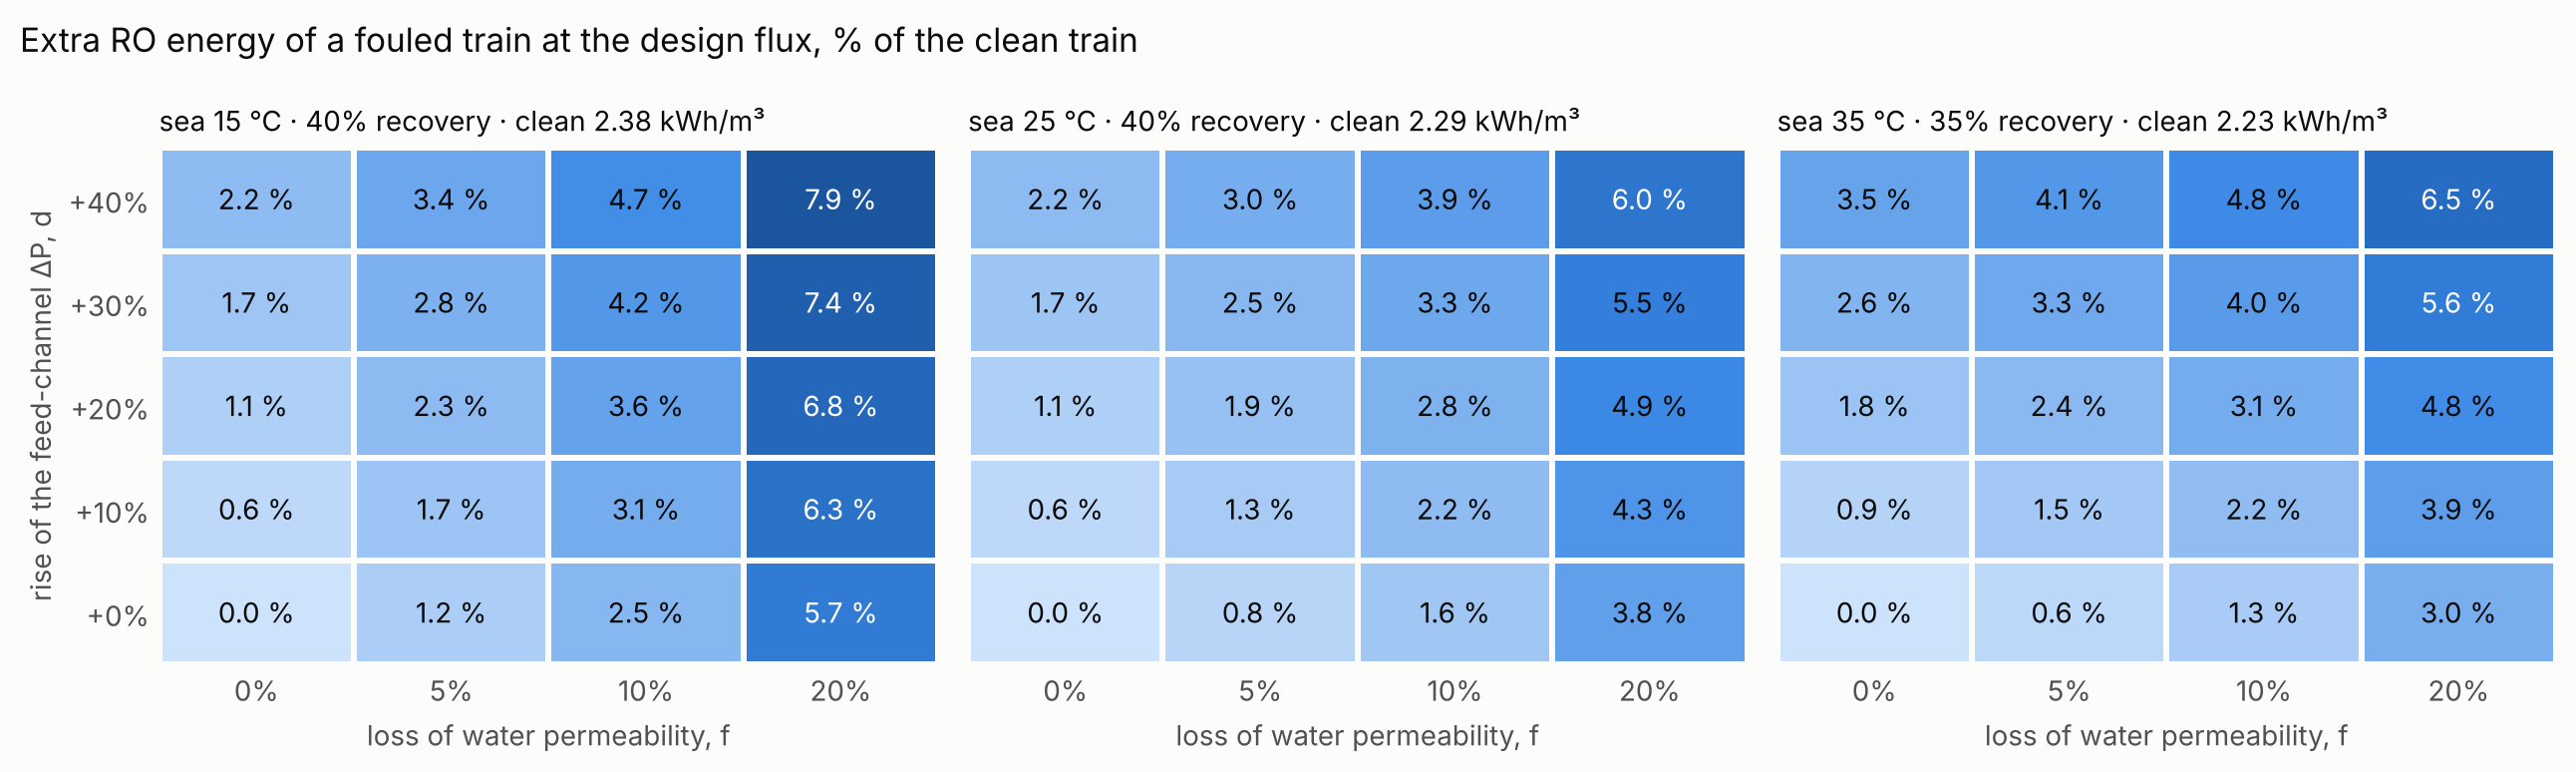

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), sharey=True)
for ax, T in zip(axes, (15.0, 25.0, 35.0)):
    g = pm[pm["T"] == T].pivot(index="d", columns="f", values="extra_pct")
    ax.pcolormesh(np.arange(len(FS) + 1), np.arange(len(DS) + 1), g.values, cmap=BLUES, vmin=0, vmax=10, edgecolors=SURF, linewidth=2)
    for i in range(len(DS)):
        for j in range(len(FS)):
            ax.text(j + 0.5, i + 0.5, f"{g.values[i, j]:.1f} %", ha="center", va="center", fontsize=10,
                    color="white" if g.values[i, j] > 5.5 else INK)
    ax.set_xticks(np.arange(len(FS)) + 0.5, [f"{x:.0%}" for x in FS]); ax.set_yticks(np.arange(len(DS)) + 0.5, [f"+{x:.0%}" for x in DS])
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    R = pm[pm["T"] == T].R.iloc[0]
    ax.set_title(f"sea {T:.0f} °C · {R:.0%} recovery · clean {clean[T]:.2f} kWh/m³", loc="left", color=INK, fontsize=10)
    ax.set_xlabel("loss of water permeability, f")
axes[0].set_ylabel("rise of the feed-channel ΔP, d")
fig.suptitle("Extra RO energy of a fouled train at the design flux, % of the clean train", x=0.01, ha="left", color=INK, fontsize=12)
plt.tight_layout(); plt.show()

## 4 · This plant's fouling on our train

Every recorded train-day from day 300 (before that the record is sparse) gives one (d, f). A fine map at 25 °C (d 0–0.6 by 0.05,
f 0–0.3 by 0.025) is read between its points (bilinear). The question is not whether this plant used more energy — its record
has no energy — but what its fouling *would* cost on a train we know.

**Two different medians.** The first table gives the median of the 1,185 train-days' *costs* (what the run script scored E1
on). The line after it reads the map at the *median state* — the median ΔP rise with the median permeability loss, the state
section 5 holds the plant at under the name "median day". They differ because a third of the days also lost permeability,
which costs more.

In [7]:
t0 = time.time()
DG, FG = np.round(np.arange(0.0, 0.601, 0.05), 3), np.round(np.arange(0.0, 0.301, 0.025), 3)
dd, ff = (a.ravel() for a in np.meshgrid(DG, FG, indexing="ij"))
fine = np.array([v["sec_ro"] for v in operate(np.full(len(dd), 14.0), 0.40, 43.0, 25.0, d=dd, f=ff)]).reshape(len(DG), len(FG))
dep = dep_all[dep_all.day_index >= 300]

def bilinear(d, f):
    d, f = np.clip(d, DG[0], DG[-1]), np.clip(f, FG[0], FG[-1])
    i = np.clip(np.searchsorted(DG, d, side="right") - 1, 0, len(DG) - 2)
    j = np.clip(np.searchsorted(FG, f, side="right") - 1, 0, len(FG) - 2)
    u, w = (d - DG[i]) / (DG[i + 1] - DG[i]), (f - FG[j]) / (FG[j + 1] - FG[j])
    return (fine[i, j] * (1 - u) * (1 - w) + fine[i + 1, j] * u * (1 - w) + fine[i, j + 1] * (1 - u) * w + fine[i + 1, j + 1] * u * w)

extra = bilinear(dep.dp_pct.to_numpy(), dep.flux_pct.to_numpy()) - fine[0, 0]
E1 = {"train-days": len(dep), "clean RO kWh/m3": round(fine[0, 0], 4),
      "extra kWh/m3: median, 90th pct": [round(float(np.median(extra)), 4), round(float(np.quantile(extra, 0.9)), 4)],
      "extra %: median, 90th pct": [round(float(100 * np.median(extra) / fine[0, 0]), 2), round(float(100 * np.quantile(extra, 0.9) / fine[0, 0]), 2)],
      "share beyond the map (d, f)": [round(float((dep.dp_pct > DG[-1]).mean()), 4), round(float((dep.flux_pct > FG[-1]).mean()), 4)]}
print(f"[{time.time() - t0:.0f} s]"); display(pd.Series(E1, name="days 300-771 on our train, 25 C").to_frame())
# the same map read at two single states (section 5 holds the plant at them): not the same as the medians above
MED = (float(dep.dp_pct.median()), float(dep.flux_pct.median())); P90 = (float(dep.dp_pct.quantile(0.9)), float(dep.flux_pct.quantile(0.9)))
STATE_PCT = {k: float(100 * (bilinear(*v) - fine[0, 0]) / fine[0, 0]) for k, v in (("median state", MED), ("both at their 90th percentile", P90))}
for k, v in (("median state", MED), ("both at their 90th percentile", P90)):
    print(f"{k} (d {v[0]:.3f}, f {v[1]:.3f}): +{STATE_PCT[k]:.2f} % RO energy — the median of the days' costs is {E1['extra %: median, 90th pct'][0]} %,",
          f"their 90th percentile {E1['extra %: median, 90th pct'][1]} %")

[51 s]


,"days 300-771 on our train, 25 C"
train-days,1185
clean RO kWh/m3,2.2882
"extra kWh/m3: median, 90th pct","[0.0253, 0.0788]"
"extra %: median, 90th pct","[1.11, 3.44]"
"share beyond the map (d, f)","[0.0, 0.0]"


median state (d 0.161, f 0.000): +0.90 % RO energy — the median of the days' costs is 1.11 %, their 90th percentile 3.44 %
both at their 90th percentile (d 0.341, f 0.129): +4.14 % RO energy — the median of the days' costs is 1.11 %, their 90th percentile 3.44 %


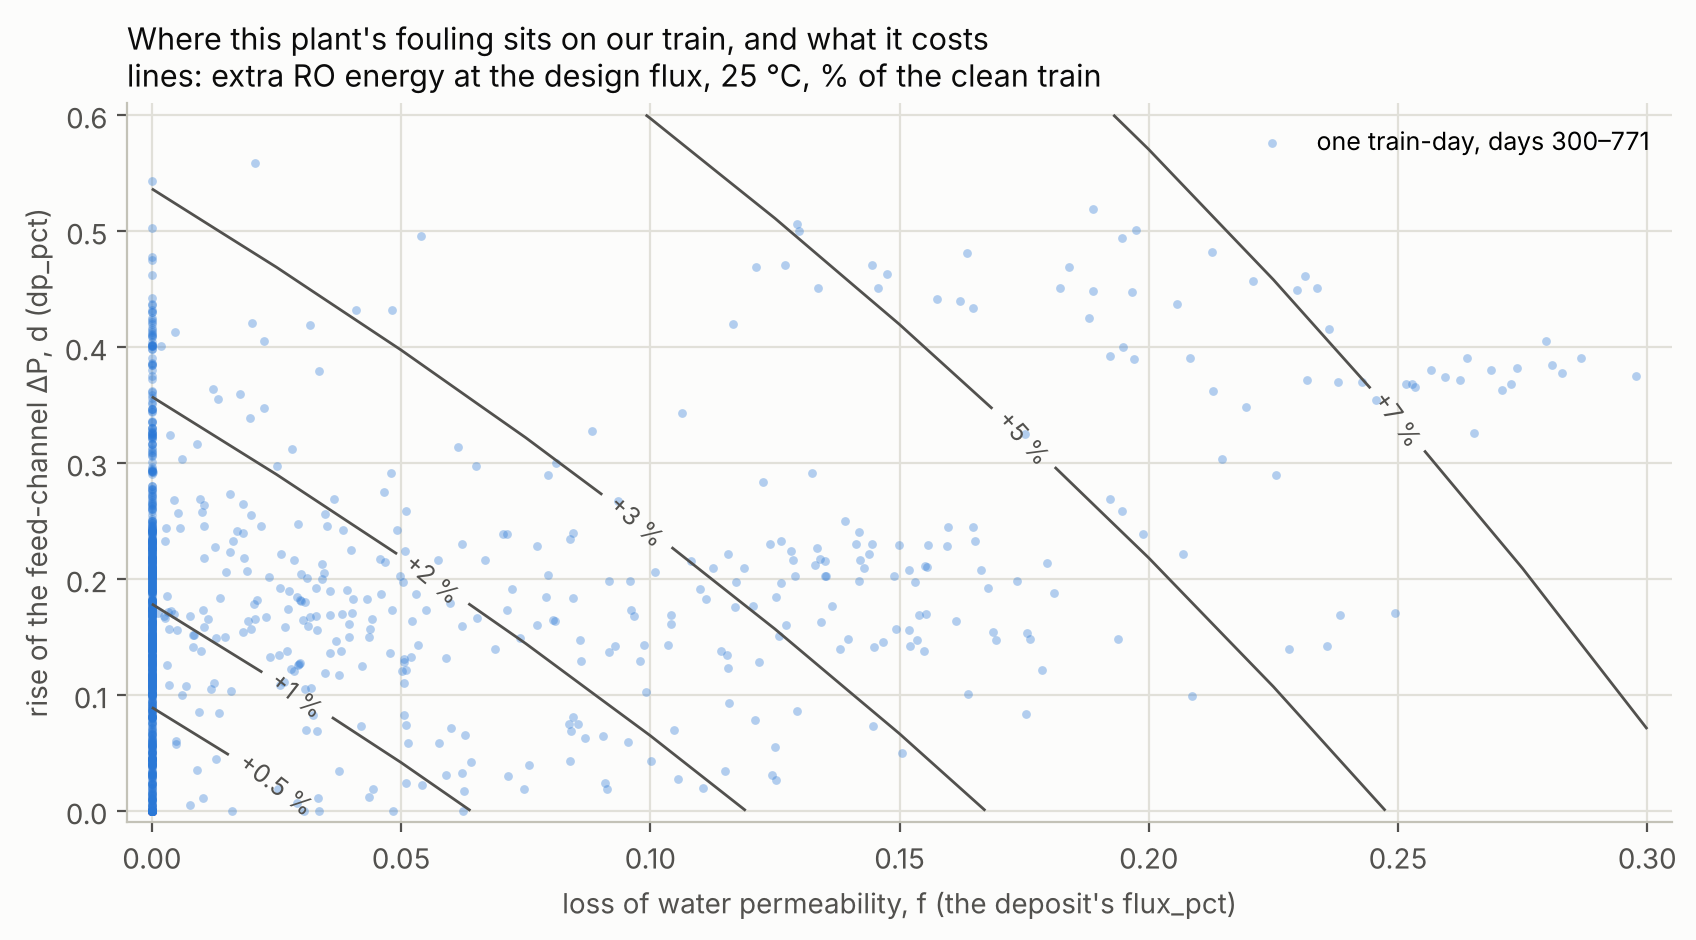

In [8]:
fig, ax = plt.subplots(figsize=(8.6, 4.8)); style(ax)
ax.scatter(dep.flux_pct.clip(upper=FG[-1]), dep.dp_pct.clip(upper=DG[-1]), s=10, color=BLUE, alpha=0.35, lw=0, label="one train-day, days 300–771")
pct = 100 * (fine - fine[0, 0]) / fine[0, 0]
cs = ax.contour(FG, DG, pct, levels=[0.5, 1, 2, 3, 5, 7], colors=INK2, linewidths=1)
ax.clabel(cs, fmt=lambda x: f"+{x:g} %", fontsize=9)
ax.set_xlabel("loss of water permeability, f (the deposit's flux_pct)"); ax.set_ylabel("rise of the feed-channel ΔP, d (dp_pct)")
ax.set_xlim(-0.005, FG[-1] + 0.005); ax.set_ylim(-0.01, DG[-1] + 0.01)
ax.legend(frameon=False, fontsize=9, loc="upper right")
ax.set_title("Where this plant's fouling sits on our train, and what it costs\n"
             "lines: extra RO energy at the design flux, 25 °C, % of the clean train", loc="left", color=INK, fontsize=11)
plt.tight_layout(); plt.show()

## 5 · A year under the sun, fouled

2024, with every train held all year at one fouling state: **clean**; the plant's **median day** (the median ΔP rise and the
median permeability loss — the median state of section 4); the level its **operators
cleaned at** (the median over its cleanings of the ΔP they saw in the last 7 recorded days before each — 22.8 % — with the
median permeability loss on those days); and **both at their 90th percentile**. A fouled train has its own operating table
(phase 2's, recomputed), so the plant knows its own energy curve; it keeps the clean plant's recovery plan (35 % at 35 °C), so
the difference is fouling alone. *(Changed after the first run — see the appendix: at the 90th-percentile state the fouled train
could run 40 % even at 35 °C; that variant is shown as a sensitivity.)* Two strategies, as in phase 2: **steady** (a plant the size
of the demand, at the demand rate) and the **rule** (2× demand, 0.8 kWp per m³/day, 12-hour tank, no forecast).

**Who pays the penalty:** the grid share of the penalty = extra grid kWh/m³ ÷ extra total kWh/m³. Under the rule, part of the
extra energy falls at noon, when the sun has more than enough; part does not.

In [9]:
t0 = time.time()
legs = {}
for t, g in dep_all.groupby("train"):                     # the cleaning legs the table was built on
    legs[t] = sorted({int(round(v)) for v in pd.concat([(g.day_index - g.days_since_cip).dropna(), (g.day_index + g.days_to_next_cip).dropna()])})
seen = []
for t, ls in legs.items():                                # campaigns: legs within 7 days are one cleaning
    camps = []
    for x in ls:
        if camps and x - camps[-1][1] <= 7:
            camps[-1][1] = x
        else:
            camps.append([x, x])
    g = dep_all[dep_all.train == t].set_index("day_index")
    for a, _ in camps:
        before = g[g.index < a]
        if len(before):
            w = before[before.index > before.index.max() - 7]          # what the operator saw: the last 7 days before it
            if len(w) >= 3 and a >= 300:
                seen.append((float(w.dp_pct.median()), float(w.flux_pct.median())))
seen = np.array(seen)
STATES = {"clean": (0.0, 0.0),
          "median day": (float(dep.dp_pct.median()), float(dep.flux_pct.median())),
          "operators' cleaning level": (round(float(np.median(seen[:, 0])), 3), float(np.median(seen[:, 1]))),   # 22.8 %, as phase 3b reported it
          "both at 90th percentile": (float(dep.dp_pct.quantile(0.9)), float(dep.flux_pct.quantile(0.9)))}
print(f"{len(seen)} cleanings with a level seen before them;", {k: (round(a, 4), round(b, 4)) for k, (a, b) in STATES.items()})
year, RUNS = [], {}
for name, (d, f) in STATES.items():
    perf, hot = (perf0, hot0) if name == "clean" else perf_table(d, f, hot=hot0)   # the clean plant's recovery plan
    c1, cC = curves(perf, 1.0, OTHER), curves(perf, CAP, OTHER)
    for strat, q, cv in (("steady", run_steady(pv_kw, T24, c1, 0), c1), ("rule", run_rule(pv_kw, T24, cC, TANK_H * DEMAND), cC)):
        RUNS[name, strat] = (q, cv)
        year.append({"state": name, "d": d, "f": f, "35 % recovery at": hot, "strategy": strat, **score(q, pv_kw, T24, cv)})
SENS = "both at 90th percentile, plan recomputed (sensitivity)"
d, f = STATES["both at 90th percentile"]
perf, hot = perf_table(d, f)                                 # sensitivity: the plan recomputed for the fouled train
c1, cC = curves(perf, 1.0, OTHER), curves(perf, CAP, OTHER)
for strat, q, cv in (("steady", run_steady(pv_kw, T24, c1, 0), c1), ("rule", run_rule(pv_kw, T24, cC, TANK_H * DEMAND), cC)):
    year.append({"state": SENS, "d": d, "f": f, "35 % recovery at": hot, "strategy": strat, **score(q, pv_kw, T24, cv)})
year = pd.DataFrame(year)
base = year[year.state == "clean"].set_index("strategy")
year["extra kWh/m3"] = year["kWh/m3"] - year.strategy.map(base["kWh/m3"])
year["extra grid kWh/m3"] = year["grid kWh/m3"] - year.strategy.map(base["grid kWh/m3"])
year["grid share of the penalty"] = year["extra grid kWh/m3"] / year["extra kWh/m3"]
print(f"[{time.time() - t0:.0f} s]")
display(year[["state", "strategy", "kWh/m3", "grid kWh/m3", "solar share %", "extra kWh/m3", "extra grid kWh/m3",
              "grid share of the penalty", "hours short", "35 % recovery at"]].round(4))

17 cleanings with a level seen before them; {'clean': (0.0, 0.0), 'median day': (0.1609, 0.0), "operators' cleaning level": (0.228, 0.0), 'both at 90th percentile': (0.3412, 0.1295)}


[770 s]


,state,strategy,kWh/m3,grid kWh/m3,solar share %,extra kWh/m3,extra grid kWh/m3,grid share of the penalty,hours short,35 % recovery at
0,clean,steady,3.5342,2.0715,41.3881,0.0000,0.0000,NaN,0,[35.0]
1,clean,rule,3.5326,0.7331,79.2486,0.0000,0.0000,NaN,0,[35.0]
2,median day,steady,3.5554,2.0851,41.3544,0.0212,0.0136,0.6426,0,[35.0]
3,median day,rule,3.5531,0.7624,78.5415,0.0205,0.0294,1.4306,0,[35.0]
4,operators' cleaning level,steady,3.5643,2.0908,41.3403,0.0301,0.0193,0.6427,0,[35.0]
5,operators' cleaning level,rule,3.5617,0.7657,78.5014,0.0291,0.0327,1.1213,0,[35.0]
6,both at 90th percentile,steady,3.6299,2.1334,41.2258,0.0957,0.0620,0.6477,0,[35.0]
7,both at 90th percentile,rule,3.6194,0.6989,80.6896,0.0868,-0.0341,-0.3932,0,[35.0]
8,"both at 90th percentile, plan recomputed (sens...",steady,3.6201,2.1274,41.2336,0.0859,0.0559,0.6512,0,[]
9,"both at 90th percentile, plan recomputed (sens...",rule,3.6089,0.7109,80.3015,0.0764,-0.0221,-0.2900,0,[]


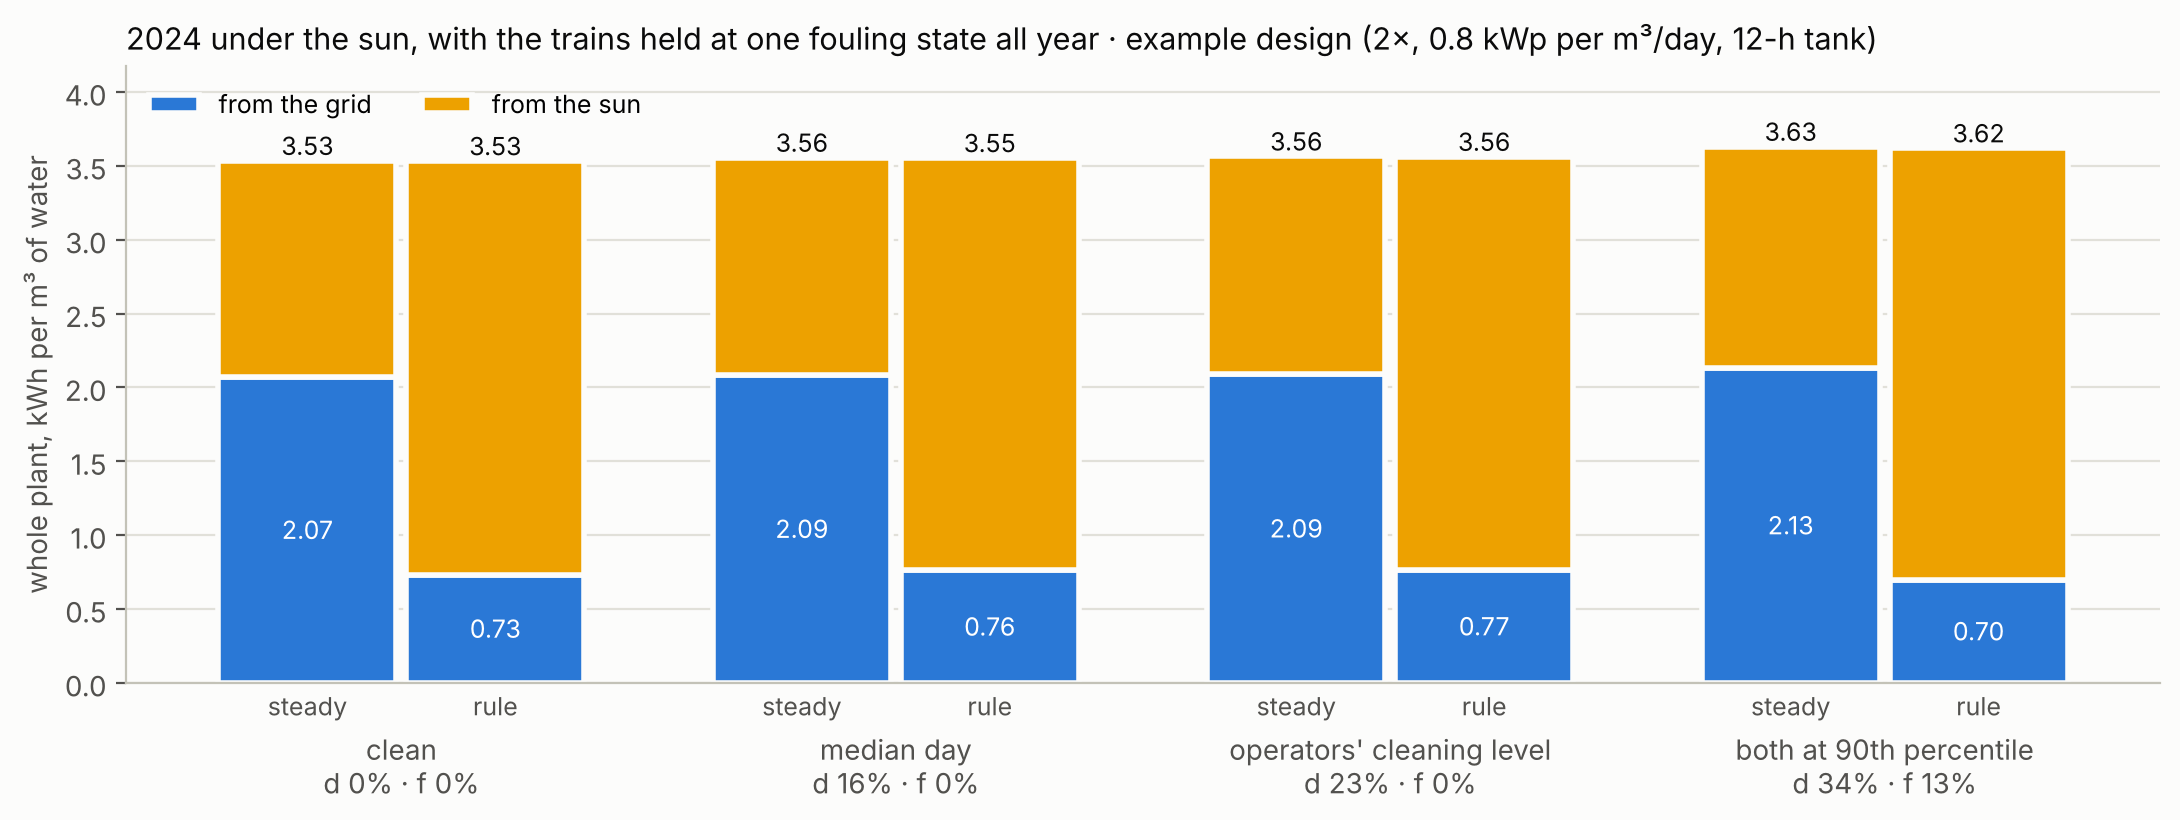

In [10]:
fig, ax = plt.subplots(figsize=(11, 4.2)); style(ax); ax.grid(axis="x", visible=False)
names = list(STATES); x = np.arange(len(names)); w = 0.36
for k, (strat, dx) in enumerate((("steady", -w / 2 - 0.01), ("rule", w / 2 + 0.01))):
    g = year[(year.strategy == strat) & (year.state != SENS)].set_index("state").loc[names]
    sun_part = g["kWh/m3"] - g["grid kWh/m3"]
    ax.bar(x + dx, g["grid kWh/m3"], w, color=BLUE, label="from the grid" if k == 0 else None, edgecolor=SURF, linewidth=2)
    ax.bar(x + dx, sun_part, w, bottom=g["grid kWh/m3"], color=YELLOW, label="from the sun" if k == 0 else None, edgecolor=SURF, linewidth=2)
    for xi, (tot, grid) in enumerate(zip(g["kWh/m3"], g["grid kWh/m3"])):
        ax.text(xi + dx, tot + 0.04, f"{tot:.2f}", ha="center", fontsize=9, color=INK)
        ax.text(xi + dx, grid / 2, f"{grid:.2f}", ha="center", va="center", fontsize=9, color="white")
        ax.text(xi + dx, -0.22, strat, ha="center", fontsize=9, color=INK2)
ax.set_xticks(x, [f"{n}\nd {STATES[n][0]:.0%} · f {STATES[n][1]:.0%}" for n in names]); ax.tick_params(axis="x", length=0, pad=18)
ax.set_ylabel("whole plant, kWh per m³ of water"); ax.set_ylim(0, year["kWh/m3"].max() * 1.15)
ax.legend(frameon=False, fontsize=9, loc="upper left", ncol=2)
ax.set_title("2024 under the sun, with the trains held at one fouling state all year · example design (2×, 0.8 kWp per m³/day, 12-h tank)",
             loc="left", color=INK, fontsize=11)
plt.tight_layout(); plt.show()

### 5a · Why the sun-following plant's share is above 1, or below 0 — descriptive, added after the run

The rule strategy makes as much water as the sun can power, within each train's **operating window**: the part of phase 2's
6–17 LMH table where every limit holds. In cool water its edges are the table's own ends and the brine-flow minimum; in warm
water they are set by the first (lead) element's limits — 32 LMH of flux and 13 % recovery. Fouling moves those edges.

- **ΔP fouling** (the median day: d = 16 %, no permeability loss) leaves less driving pressure for the last elements, so the lead
  element takes a little more of the work. At the window's edges it crosses its limits — at 27 °C and 17 LMH its flux goes from
  31.98 to 32.21 LMH, at 19 °C and 8 LMH its recovery from 12.98 to 13.01 % (the last table above). On the table's 1-LMH steps
  the window loses a step at several temperatures. The plant makes less water by day, more at night — from the grid.
- **Permeability loss** (the 90th-percentile state: f = 13 %) needs more pressure everywhere, which spreads the flux more evenly
  along the vessel. The lead element works less (33 °C, 15 LMH: 32.62 → 30.79 LMH), the window widens, and the plant follows
  the sun further — buying less from the grid than when clean, while using more energy in all.

So for a plant that follows the sun, the grid's part of the fouling penalty is not a fixed share: it is set by where the
window's edges fall. The edges move by whole steps for small changes — the clean train sits within a few hundredths of its
limits at several points (31.98 against 32 LMH; 12.98 against 13 %). The steady plant, which does not use its window, shows a stable share.

In [11]:
rows, split = [], []
for name in ("clean", "median day", "both at 90th percentile"):
    q, cv = RUNS[name, "rule"]
    for T, c in sorted(cv.items()):
        rows.append({"state": name, "sea, °C": T, "recovery": f"{c['R']:.0%}", "lowest flux": round(14 * c["f_min"], 1),
                     "highest flux": round(14 * c["q_max"] / (TRAINS * c["Q_tr"]), 1)})
    E, _, _ = hourly(q, T24, cv); used = np.minimum(E, pv_kw)
    split.append({"state": name, "sun used, MWh": round(used.sum() / 1000, 1), "grid, MWh": round((E - used).sum() / 1000, 1),
                  "water made at night, m³": round(q[pv_kw <= 0].sum()), "water made, m³": round(q.sum())})
win = pd.DataFrame(rows)
print("Usable flux of one train (LMH), by sea temperature — rule strategy's table, 40 % recovery (35 % at 35 °C):")
display(win.pivot(index="sea, °C", columns="state", values=["lowest flux", "highest flux"]))
print("2024, rule strategy:"); display(pd.DataFrame(split).set_index("state"))
edge = []
for T, J, other in ((27.0, 17.0, "median day"), (19.0, 8.0, "median day"), (33.0, 15.0, "both at 90th percentile")):
    for st in ("clean", other):
        v = operate([J], 0.40, 43.0, T, d=STATES[st][0], f=STATES[st][1])[0]
        edge.append({"sea, °C": T, "flux, LMH": J, "state": st, "first element's flux, LMH (limit 32)": round(float(v["lead_flux"]), 2),
                     "first element's recovery, % (limit 13)": round(100 * float(v["lead_recovery"]), 2), "limits": flags(v)})
print("At the window's edges, 40 % recovery:"); display(pd.DataFrame(edge))

Usable flux of one train (LMH), by sea temperature — rule strategy's table, 40 % recovery (35 % at 35 °C):


lowest flux                             highest flux                 
state   both at 90th percentile clean median day both at 90th percentile clean median day
sea, °C                                                                                  
15.0                        8.0   8.0        8.0                    17.0  17.0       17.0
17.0                        8.0   8.0        8.0                    17.0  17.0       17.0
19.0                        8.0   8.0        9.0                    17.0  17.0       17.0
21.0                        8.0   9.0        9.0                    17.0  17.0       17.0
23.0                        9.0  10.0       10.0                    17.0  17.0       17.0
25.0                        9.0  11.0       11.0                    17.0  17.0       17.0
27.0                       10.0  11.0       12.0                    17.0  17.0       16.0
29.0                       11.0  12.0       12.0                    17.0  16.0       15.0
31.0                       11.0  13.0       13.0                    16.0  15.0       15.0
33.0                       12.0  14.0       14.0                    15.0  14.0       14.0
35.0                        9.0   9.0        9.0                    17.0  16.0       15.0

2024, rule strategy:


,"sun used, MWh","grid, MWh","water made at night, m³","water made, m³"
state,,,,
clean,1024.9,268.4,61569,366090
median day,1021.6,279.1,63944,366089
both at 90th percentile,1069.1,255.9,57618,366084


At the window's edges, 40 % recovery:


,"sea, °C","flux, LMH",state,"first element's flux, LMH (limit 32)","first element's recovery, % (limit 13)",limits
0,27.0,17.0,clean,31.98,10.75,ok
1,27.0,17.0,median day,32.21,10.83,lead flux
2,19.0,8.0,clean,18.17,12.98,ok
3,19.0,8.0,median day,18.21,13.01,lead recovery
4,33.0,15.0,clean,32.62,12.43,lead flux
5,33.0,15.0,both at 90th percentile,30.79,11.73,ok


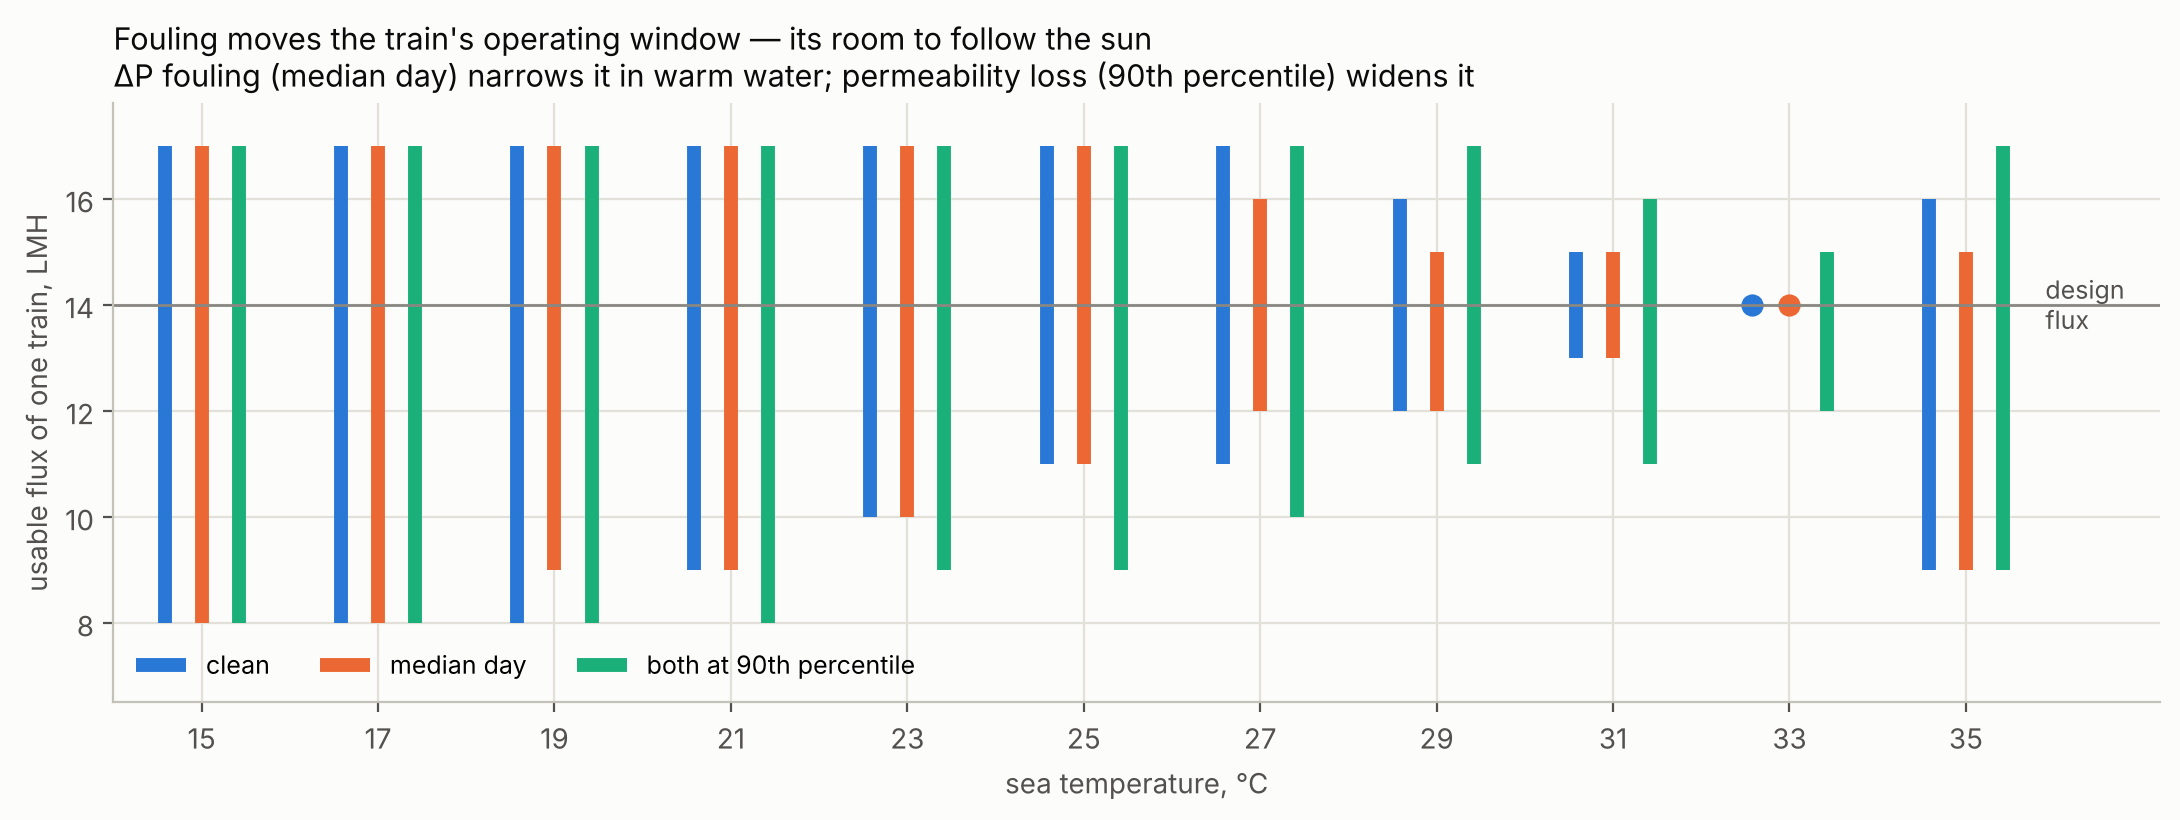

In [12]:
fig, ax = plt.subplots(figsize=(11, 4.2)); style(ax)
cols = {"clean": BLUE, "median day": ORANGE, "both at 90th percentile": AQUA}
for k, (name, col) in enumerate(cols.items()):
    g = win[win.state == name]
    x = g["sea, °C"] + (k - 1) * 0.42
    ax.vlines(x, g["lowest flux"], g["highest flux"], color=col, lw=5, label=name)
    one = (g["lowest flux"] == g["highest flux"]).to_numpy()              # a window of a single point
    ax.plot(x[one], g["lowest flux"][one], "o", color=col, ms=7)
ax.axhline(14, color=MUTED, lw=1); ax.text(35.9, 14, "design\nflux", color=INK2, fontsize=9, va="center")
ax.set_xticks(sorted(win["sea, °C"].unique())); ax.set_xlim(14, 37.2); ax.set_ylim(6.5, 17.8)
ax.set_xlabel("sea temperature, °C"); ax.set_ylabel("usable flux of one train, LMH")
ax.legend(frameon=False, fontsize=9, loc="lower left", ncol=3)
ax.set_title("Fouling moves the train's operating window — its room to follow the sun\n"
             "ΔP fouling (median day) narrows it in warm water; permeability loss (90th percentile) widens it", loc="left", color=INK, fontsize=11)
plt.tight_layout(); plt.show()

## 6 · When would energy alone clean — with the sun?

Project 5's question on the same 15 complete cycles: each day, the live cost of fouling is the extra energy the train spends to
hold its production, times the price of electricity; a cleaning costs F (USD per m³/day of capacity). The rule cleans when that
live cost reaches the cycle's average cost so far, the cleaning's own cost included (Project 5, Part D: 7-day smoothing, no
decision in the first 7 days). Two changes, both declared:

- **our train's constants** instead of Project 5's assumed ones: the clean net driving pressure (14 LMH ÷ the membrane's
  permeability at 25 °C), the clean vessel's pressure drop, and the energy per bar of feed pressure — all from the model above;
- **the sun pays its part:** the price × the grid share of the penalty from section 5 — the largest of the three fouled states,
  the one most in favour of cleaning. (The declaration said only "the grid share of item 3"; the largest was coded before the
  first run. The other two states' shares are shown after the table.)

Counted: the cycles in which energy alone would have cleaned before the operators did, for every price and F of Project 5.
The check comes first: with Project 5's own constants and no sun, its published mid case (0 of 15) must come back.

In [13]:
t0 = time.time()
A25 = MEM["A20"] * tcf(25.0) / tcf(20.0)
v0 = operate([14.0], 0.40, 43.0, 25.0)[0]
NDP0, DP0 = 14.0 / A25, v0["P_f"] - float(v0["P_brine"])           # the clean train's net driving pressure and vessel dP
KWH_BAR = (sec_ro(v0["P_f"] + 0.5, v0["Q_f"], float(v0["Q_p"]), float(v0["P_brine"]) + 0.5) - v0["sec_ro"]) / 0.5
fouled = year[~year.state.isin(["clean", SENS])]
fy_states = ["median day", "operators' cleaning level", "both at 90th percentile"]
SHARE = {"no sun (Project 5)": 1.0,
         "steady, with panels": float(fouled[fouled.strategy == "steady"]["grid share of the penalty"].max()),
         "rule, with panels": float(fouled[fouled.strategy == "rule"]["grid share of the penalty"].max())}
cycles = cycle_inputs(load_daily(DAILY))

def count(price, F, kwh_bar, ndp0, dp0):
    n = 0
    for c in cycles:
        m = price * fouling_energy_penalty(c["ndp"], c["d_dp"], ndp0, dp0, kwh_bar)      # USD per m3, day by day
        n += int(interval_economics(c["day"], m, F, smooth=SMOOTH_DAYS, min_t=MIN_DAYS).rule_time is not None)
    return n

p5_mid = count(MID["price"], MID["F"], specific_energy_per_bar(erd_eff=0.95), MID["ndp0"], MID["dp0"])
assert p5_mid == 0
print(f"check: Project 5's mid case with its own constants: {p5_mid} of {len(cycles)} cycles, as published")
print(f"our train's constants: clean NDP {NDP0:.2f} bar, vessel dP {DP0:.3f} bar, {KWH_BAR:.4f} kWh/m3 per bar of feed pressure",
      f"(Project 5 assumed {MID['ndp0']:.0f} bar, {MID['dp0']:.0f} bar, {specific_energy_per_bar():.4f})")
print("grid share of the penalty used (the largest of the three fouled states):", {k: round(v, 3) for k, v in SHARE.items()})
grid = pd.DataFrame([{"price USD/kWh": p, "F USD per m3/day": F, **{k: count(p * s, F, KWH_BAR, NDP0, DP0) for k, s in SHARE.items()}}
                     for p, F in itertools.product(P5_GRID["price"], P5_GRID["F"])])
print(f"[{time.time() - t0:.0f} s]  cycles (of {len(cycles)}) in which energy alone would have cleaned before the operators did:")
display(grid)
ALT = {s: float(fouled[(fouled.strategy == "rule") & (fouled.state == s)]["grid share of the penalty"].iloc[0]) for s in fy_states}
print("sensitivity, sun-following plant — each fouled state's own grid share, and the most cycles it gives over all prices and F:",
      {s: (round(v, 3), max(count(p * v, F, KWH_BAR, NDP0, DP0) for p, F in itertools.product(P5_GRID["price"], P5_GRID["F"]))) for s, v in ALT.items()})

check: Project 5's mid case with its own constants: 0 of 15 cycles, as published
our train's constants: clean NDP 12.44 bar, vessel dP 1.824 bar, 0.0344 kWh/m3 per bar of feed pressure (Project 5 assumed 20 bar, 2 bar, 0.0368)
grid share of the penalty used (the largest of the three fouled states): {'no sun (Project 5)': 1.0, 'steady, with panels': 0.648, 'rule, with panels': 1.431}


[17 s]  cycles (of 15) in which energy alone would have cleaned before the operators did:


,price USD/kWh,F USD per m3/day,no sun (Project 5),"steady, with panels","rule, with panels"
0,0.05,0.5,0,0,0
1,0.05,1.0,0,0,0
2,0.05,2.0,0,0,0
3,0.05,5.0,0,0,0
4,0.10,0.5,0,0,0
5,0.10,1.0,0,0,0
6,0.10,2.0,0,0,0
7,0.10,5.0,0,0,0
8,0.15,0.5,1,0,2
9,0.15,1.0,0,0,0


sensitivity, sun-following plant — each fouled state's own grid share, and the most cycles it gives over all prices and F: {'median day': (1.431, 2), "operators' cleaning level": (1.121, 2), 'both at 90th percentile': (-0.393, 0)}


## 7 · The four expectations, written before the run

In [14]:
v90 = operate([14.0], 0.40, 43.0, 25.0, d=STATES["both at 90th percentile"][0], f=STATES["both at 90th percentile"][1])[0]
fy = fouled.set_index(["state", "strategy"])["grid share of the penalty"].unstack()
display(fy.round(3))
E = pd.DataFrame([
    ("E1", "the plant's median fouling day costs < 1 % of the clean RO energy (25 C)",
     f"median of the train-days' costs {E1['extra %: median, 90th pct'][0]} %; the median state {STATE_PCT['median state']:.2f} %",
     "no, as scored (the days' costs); yes for the median state" if E1["extra %: median, 90th pct"][0] >= 1.0 and STATE_PCT["median state"] < 1.0
     else str(E1["extra %: median, 90th pct"][0] < 1.0)),
    ("E2", "the rule leaves a smaller share of the penalty to the grid than steady", ", ".join(f"{s}: {r.rule:.2f} vs {r.steady:.2f}" for s, r in fy.iterrows()),
     "yes" if (fy["rule"] < fy["steady"]).all() else "no"),
    ("E3", "with the sun, energy cleans before the operators in no more cycles",
     f"max {grid['no sun (Project 5)'].max()} without, {grid['steady, with panels'].max()} steady, {grid['rule, with panels'].max()} rule",
     "yes" if ((grid["steady, with panels"] <= grid["no sun (Project 5)"]).all() and (grid["rule, with panels"] <= grid["no sun (Project 5)"]).all()) else "no"),
    ("E4", "at the 90th-percentile state no element passes 1 bar (25 C, design flux)",
     f"largest element {float(v90['max_el_dp']):.3f} bar, lead {float(v90['lead_el_dp']):.3f}; limits: {flags(v90)}", "yes" if float(v90["max_el_dp"]) <= 1.0 else "no")],
    columns=["", "expected before the run", "result", "held"])
with pd.option_context("display.max_colwidth", None):   # show every cell in full
    display(E)

strategy,rule,steady
state,,
both at 90th percentile,-0.393,0.648
median day,1.431,0.643
operators' cleaning level,1.121,0.643


,,expected before the run,result,held
0,E1,the plant's median fouling day costs < 1 % of the clean RO energy (25 C),median of the train-days' costs 1.11 %; the median state 0.90 %,"no, as scored (the days' costs); yes for the median state"
1,E2,the rule leaves a smaller share of the penalty to the grid than steady,"both at 90th percentile: -0.39 vs 0.65, median day: 1.43 vs 0.64, operators' cleaning level: 1.12 vs 0.64",no
2,E3,"with the sun, energy cleans before the operators in no more cycles","max 1 without, 0 steady, 2 rule",no
3,E4,"at the 90th-percentile state no element passes 1 bar (25 C, design flux)","largest element 0.529 bar, lead 0.529; limits: ok",yes


## What it means

- **This plant's fouling costs our train little energy.** At 25 °C, half the recorded train-days would cost more than
  **1.1 %** of the clean RO energy (0.025 kWh/m³), the worst tenth of days more than 3.4 % (0.079 kWh/m³). A point of
  permeability loss costs more than a point of ΔP rise — about three times at 25 °C (20 % less permeability: +3.8 %; 40 % more
  ΔP: +2.2 %). Every point of the map passes every limit, and so does the 90th-percentile state at 25 °C (E4: largest element
  ΔP 0.53 bar, against 1 bar); recorded days beyond the map (ΔP rise above 40 %, or permeability loss above 20 %) were not
  checked for limits.
- **E1 depends on which median is meant.** The run script, written before the run, scored the median of the days' costs:
  1.11 %, so E1 missed, narrowly. Read as the median *state* (median ΔP rise, median permeability loss) — the "median day" of
  section 5 — the cost is 0.90 %, under 1 %. The declaration's words allow both; both are reported.
- **Who pays depends on the plant.** The steady plant buys about **64–65 %** of its fouling penalty from the grid, in every
  state. For the sun-following plant there is no such share: **143 %** and **112 %** at the median day and the operators'
  cleaning level — the grid pays more than the whole penalty — and **−39 %** at the 90th-percentile state, where the plant
  buys less from the grid than when clean. E2 expected the rule to leave a smaller share to the grid than steady operation: it
  did not hold. The cause (5a) is the operating window, which fouling moves in whole steps. For a plant that follows the sun,
  what fouling does to the window matters more than what it does to the kWh per m³.
- **Energy is still not a reason to clean — with or without the sun.** With our train's own constants (clean net driving
  pressure 12.4 bar, vessel ΔP 1.82 bar, 0.034 kWh/m³ per bar — Project 5 assumed 20 bar, 2 bar and 0.037), energy alone
  would have cleaned before the operators in **at most 1 of the 15 cycles** without the sun, and only at the dearest power and
  the cheapest cleaning (0.15 USD/kWh, F = 0.5); in the other 11 price × cost cases, in none. With the sun: none for the steady
  plant, and **2** for the sun-following plant at that same corner — because the grid share used, 1.43, is above 1 (with the
  cleaning level's share, 1.12, also 2; with the 90th-percentile state's, −0.39, none). E3 expected no more cycles with the
  sun than without: it failed at that one corner. Project 5's answer stands on our train.
- **Of the four expectations, E4 held, E2 and E3 failed, and E1 depends on its own wording.** E2 and E3 failed for one reason
  the expectations did not consider: a sun-following plant's grid use is set by its operating window.

**Limits.** Fouling is spread evenly along the vessel here; real fouling is not (biofouling is heavier at the feed end, scale
at the brine end), and that would move the window differently. The window effect rests on the limits treated as hard lines,
on a 1-LMH table. The real plant's fouling is relative to its own baseline: on our train it is a what-if. A state held all
year shows the most that state can do; a real year passes through it. One year (2024), one design (2×, 0.8 kWp per m³/day, 12-hour tank).

## Appendix · the declaration, as written before the run, with its changes

### Phase 4 — Fouling's energy on a plant that runs on the sun, and whether the sun changes when to clean: declared before any number is computed

Written 29 October 2026, before any fouled-train energy, fouled year or cleaning interval was computed. Nothing here will be
changed after seeing a result; any later change is listed as a change, with its reason, next to the original.

#### Why

The merged RO project has two goals. Each has its answer so far:

- **Fouling forecast.** With the routine daily indicators of the public plant, no method beat *no change* for ΔP, 1–14 days
  ahead (phase 3; Project 3 and Project 6 agree). A simulator that would have shown the value of logging the causes could not be
  made to behave like the plant (phase 3b, stopped).
- **Energy.** The phase-2 plant, twice its demand in size with 0.8 kWp of panels per m³/day and a 12-hour tank, runs about four
  fifths on the sun with no forecast. And on this plant, energy alone paid for an RO cleaning before the operators cleaned in
  0 of 15 cycles in Project 5's mid case, and in at most 6 of 15 across its 216 price-and-plant cases (Project 5, Part D).

Phase 4 joins them on one train: **how much energy does this plant's fouling cost, and does running on the sun change when
energy alone would clean?**

#### Inputs — all from earlier work, nothing new is fitted

- **The train and the year (phase 2):** seven FilmTec SW30HRLE-440 elements fitted to the datasheet, 43 g/L, design flux
  14 LMH, 40 % recovery (35 % where the hot sea needs it), every FilmTec limit; per 1,000 m³/day of demand, 8 trains; the rest of
  the plant at 65/35; sun and sea of 2024 from NASA POWER; the **steady** strategy (normal plant, demand every hour) and the
  **rule** strategy (the example design: 2×, 0.8 kWp per m³/day, 12-hour tank).
- **The fouling (the public deposit):** per train-day, days 300–771: `dp_pct` (ΔP rise on a fixed commissioning baseline) and
  `flux_pct` (loss of 25 °C specific flux, fixed baseline, floored at 0); for the cleaning question, Project 5's inputs exactly:
  the 15 complete cycles, `ndp_pct` (the net driving pressure's rise since the last cleaning — this indicator is reset at each
  cleaning, as Project 3 found) and the ΔP rise above the cycle's start.
- **The cleaning economics (Project 5, Part D):** its live cost, rule and square-root law, its first-3-days skip, 7-day smoothing
  and 7-day floor; its price grid 0.05, 0.10, 0.15 USD/kWh and cleaning cost F 0.5, 1, 2, 5 USD per m³/day of capacity.

#### Fouling on the model train

Every element's feed-channel pressure drop × (1 + d); the membrane's water permeability × (1 − f); salt permeability unchanged.
d and f come from the deposit: this plant's fouling, put on our train — a what-if, since the deposit gives no absolute pressures.

#### What is computed (and nothing else)

1. **The penalty map.** At the design point (14 LMH): feed pressure, RO energy and the limits, for d = 0, 0.1, 0.2, 0.3, 0.4 ×
   f = 0, 0.05, 0.10, 0.20, at 15, 25 and 35 °C; the extra RO energy over the clean train, in kWh/m³ and in % of it.
2. **This plant's fouling on our train.** Every train-day's (d, f), days 300–771, at 25 °C (a fine map, interpolated): the
   median and the 90th percentile of the extra RO energy.
3. **A year under the sun, fouled.** 2024, with the trains held all year at one state: clean; the plant's median day
   (d and f at their medians); the level its operators cleaned at (the fingerprint's 22.8 % with that level's median f); both at
   their 90th percentiles. Holding a state all year is an upper bound for it, not a schedule. Per strategy (steady, rule): total
   and grid kWh/m³, solar share, and the **grid share of the fouling penalty** = extra grid kWh ÷ extra total kWh.
4. **When would energy alone clean, with the sun?** Project 5's rule and law on the 15 cycles, with the phase-2 train's own
   constants instead of Project 5's assumed ones — the clean net driving pressure (14 LMH ÷ the membrane's permeability at 25 °C),
   the clean vessel's pressure drop and the energy per bar of feed pressure, from the model — and the price multiplied by the grid
   share of item 3 (the sun pays the rest). For each price × F and each strategy: the cycles in which energy alone would have
   cleaned before the operators did.

#### Written before the run — what is expected

- **E1.** On our train at 25 °C, the plant's median fouling day costs less than 1 % of the clean RO energy.
- **E2.** Under the rule strategy, the grid carries a smaller share of the fouling penalty than under the steady strategy.
- **E3.** With the sun, energy alone cleans before the operators in no more cycles than without it, at every price and F: the sun
  does not make energy a reason to clean.
- **E4.** At the 90th-percentile state, no element passes 1 bar of pressure drop at the design point at 25 °C: within this plant's
  fouling range, the element pressure-drop limit is not what fouling breaks first at the design point.

#### Checks

- With d = f = 0, the code reproduces phase 2 exactly: the design-point table and the 2024 rule and steady results.
- Item 4 with Project 5's own constants (no sun) reproduces Project 5's mid-case count.

#### Reported whatever the result

Every map value, the four states, both strategies, every price × F, and E1–E4 with pass or fail. The notebook re-runs it from
the public deposit and the public NASA POWER files.

#### Changes after the first run (29 October 2026)

- **The recovery plan is held when the train fouls.** The declaration did not say whether a fouled train keeps the clean
  plant's recovery plan (40 %, and 35 % at 35 °C, where the clean design point breaks the lead element's limits). The first run
  recomputed the plan for each fouled state, and stopped at the 90th-percentile state: there the fouled membrane — its flux
  spread more evenly along the vessel — passes the lead element's limits at 40 % even at 35 °C, so no temperature needed 35 %,
  and the code had no case for an empty list. Every fouled state now keeps the clean plant's plan, so the penalty measures
  fouling alone; the penalty map (item 1) already did. The two states that had run, the median day and the operators' cleaning
  level, kept 35 % at 35 °C either way, so their results do not change. The recomputed plan is reported as a sensitivity for
  the 90th-percentile state; it is not used in item 4 or in E1–E4.
- **E3 is checked for both strategies.** The run script first checked the rule strategy only; the declaration says "with the
  sun", which covers both. Both are now checked.
- The penalty map and the fine map were computed once, in the first run; the second run read them back (they do not depend on
  the change above).
- **E1 has two readings.** E1 speaks of "the plant's median fouling day". The run script, written before the run, scored it as
  the median of the train-days' costs (item 2); item 3 calls the median state — the median ΔP rise with the median
  permeability loss — "the plant's median day". The notebook reports both: 1.11 % and 0.90 %.
- **Which grid share prices item 4.** The declaration says "the grid share of item 3"; the run script, written before the run,
  takes the largest of the three fouled states (the one most in favour of cleaning). The notebook also shows each state's own
  share and what it gives.
- **The notebook's check of phase 2 is lighter than the run script's:** the design points, the operating table's size and the
  2024 rule result. The run script also matched phase 2's ten-year steady and rule averages.
- **Added after the run, descriptive only:** section 5a (each train's operating window by sea temperature for three states, the
  2024 split of sun and grid energy, and the first element's flux and recovery at the window's edges), the cost of the median
  and 90th-percentile states read from the 25 °C map, and the full table of the penalty map.